In [1]:
# Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import math
import ipynbname
import os
import networkx as nx

<div><h3>Contents</h3>
<ol>
    <li>Functions</li>
    <li>Network Structures</li>
    <li>Coupled Logistic Map</li>
    <li> Coupled Circle Map</li>
</ol>
</div>

<div><h2 style = "text-align:center"> Functions </h2></div>


In [2]:

# Function of coupled logistic map

def simulate_discrete_coupled(x0, f, A, t, alpha=0.1, **params):
    """
    Simulates the trajectory of a coupled map lattice over t time steps.

    Parameters:
    -----------
    x0       : 1D array of initial node states (shape: (M,))
    f        : Local map function (e.g., logistic, circle)
    A        : Adjacency matrix of the network (shape: (M, M))
    t        : Total number of time steps (length of the time series)
    alpha    : Coupling strength (float between 0 and 1)
    **params : Keyword arguments forwarded to f (e.g., r=3.8, Omega=0.5, K=1.0)

    Returns:
    --------
    traj : 2D array of shape (t, M) containing node states over time
    """
    x = np.asarray(x0, dtype=float)
    A = np.asarray(A, dtype=float)
    M = A.shape[0]

    # Precompute degrees and handle isolated nodes once outside the loop
    degree = np.sum(A, axis=1)
    degree_safe = np.where(degree == 0, 1.0, degree)
    isolated_mask = (degree == 0)

    # Allocate trajectory array: shape (t, M)
    traj = np.zeros((t, M), dtype=float)
    traj[0] = x

    # Time series simulation loop
    for step in range(1, t):
        # 1. Local dynamics
        f_x = f(x, **params)

        # 2. Network coupling
        coupling = (A @ f_x) / degree_safe
        if np.any(isolated_mask):
            coupling = np.where(isolated_mask, f_x, coupling)

        # 3. Update state
        x = (1.0 - alpha) * f_x + alpha * coupling
        traj[step] = x

    return traj

## Functions from previous notebooks
def logistic(x0, r=4):
    x0 = np.asarray(x0)
    y = r*x0*(1-x0)
    return y
    
def circle(x0, r=0.35, K=6.9115):
    x0 = np.asarray(x0)
    y= x0+r-(K/(2*math.pi))*np.sin(2*math.pi*x0)
    y = y%1
    return y

<div><h2 style = "text-align:center"> Network Structures </h2></div>

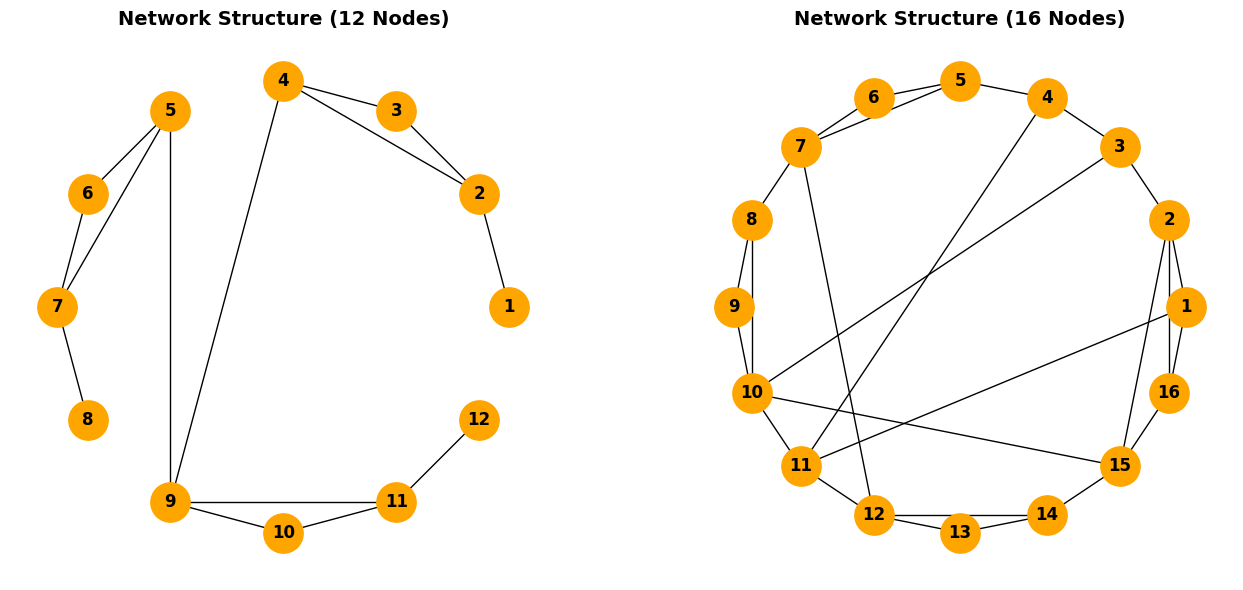

In [3]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Load adjacency matrices
network_12nodes = np.loadtxt("../../Files/12nodes.txt")
network_16nodes = np.loadtxt("../../Files/16nodes.txt")

# Create graph objects
G1 = nx.from_numpy_array(network_12nodes)
G2 = nx.from_numpy_array(network_16nodes)

G1 = nx.relabel_nodes(G1, lambda x: x + 1)
G2 = nx.relabel_nodes(G2, lambda x: x + 1)

# Set up side-by-side subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
ax1.set_aspect('equal')
ax2.set_aspect('equal')
# Plot 1: 12-node network
nx.draw(
    G1, 
    pos=nx.circular_layout(G1),   # Fixed: G1 instead of G
    ax=ax1,                      # Fixed: direct to ax1
    with_labels=True, 
    node_color='orange', 
    node_size=800, 
    font_size=12, 
    font_weight='bold', 
    edge_color='black'
)
ax1.set_title('Network Structure (12 Nodes)', fontsize=14, fontweight='bold')

# Plot 2: 16-node network
nx.draw(
    G2, 
    pos=nx.circular_layout(G2),   # Fixed: G2 instead of G
    ax=ax2,                      # Fixed: direct to ax2
    with_labels=True, 
    node_color='orange', 
    node_size=800, 
    font_size=12, 
    font_weight='bold', 
    edge_color='black'
)
ax2.set_title('Network Structure (16 Nodes)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

<div><h3> Coupled Logistic Map - Trajectory Generator </h3></div>

In [4]:
Adj = network_12nodes
M = Adj.shape[0]
rng = np.random.default_rng()
x0 = rng.random((M,))

# Works with logistic
x_next_log = simulate_discrete_coupled(x0, logistic, A=Adj, t=10**4, alpha=0.2, r=4)

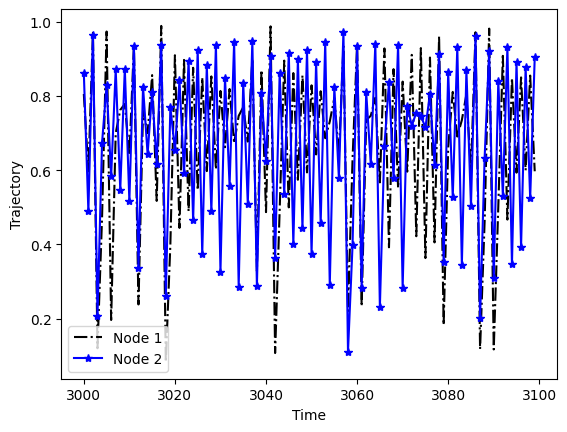

In [5]:
view_start = 3*10**3
view_end = view_start+100
plt.figure()
plt.plot(range(view_start,view_end), x_next_log[view_start:view_end,0], 'k-.', label = "Node 1")
plt.plot(range(view_start,view_end), x_next_log[view_start:view_end,1], 'b-*', label = "Node 2")
plt.xlabel("Time")
plt.ylabel("Trajectory")
plt.legend()
plt.show()

In [6]:
# Convert to DataFrame (columns 1 to N)
df = pd.DataFrame(x_next_log, columns=[f"Node_{i+1}" for i in range(x_next_log.shape[1])])

# Compute pairwise Pearson correlation
corr_matrix_df_logistic = df.corr(method="pearson")
np.fill_diagonal(corr_matrix_df_logistic.values, 0)
print(corr_matrix_df_logistic)

           Node_1    Node_2    Node_3    Node_4    Node_5    Node_6    Node_7  \
Node_1   0.000000  0.436632  0.189490  0.104337 -0.010229 -0.003720  0.016268   
Node_2   0.436632  0.000000  0.270886  0.129309  0.065009  0.007419 -0.004048   
Node_3   0.189490  0.270886  0.000000  0.194744  0.001453  0.027785  0.015659   
Node_4   0.104337  0.129309  0.194744  0.000000 -0.066817 -0.040942  0.010285   
Node_5  -0.010229  0.065009  0.001453 -0.066817  0.000000  0.285641  0.157112   
Node_6  -0.003720  0.007419  0.027785 -0.040942  0.285641  0.000000  0.264594   
Node_7   0.016268 -0.004048  0.015659  0.010285  0.157112  0.264594  0.000000   
Node_8   0.002134  0.016072  0.037749  0.001536  0.159062  0.163524  0.452844   
Node_9  -0.040449  0.006601 -0.073697  0.095268  0.091355 -0.083379  0.008790   
Node_10  0.016591 -0.039503  0.046312 -0.005686  0.019122  0.033469  0.048876   
Node_11 -0.001187  0.035417  0.015378  0.024585  0.036216  0.012863  0.014465   
Node_12  0.011313 -0.004270 

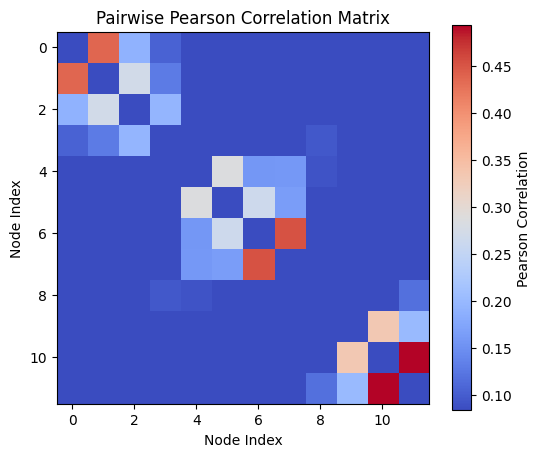

In [7]:
plt.figure(figsize=(6, 5))
plt.imshow(abs(corr_matrix_df_logistic), cmap="coolwarm", vmin=abs(np.min(corr_matrix_df_logistic)), vmax=abs(np.max(corr_matrix_df_logistic)))
plt.colorbar(label="Pearson Correlation")
plt.title("Pairwise Pearson Correlation Matrix")
plt.xlabel("Node Index")
plt.ylabel("Node Index")
plt.show()

In [8]:
abs(np.min(corr_matrix_df_logistic))

0.0833792552542984

<div><h3> Coupled Circle Map - Trajectory Generator </h3></div>

In [9]:
# Works with circle map

x_next_circ = simulate_discrete_coupled(x0, circle, A= Adj, t=10**4, alpha=0.1, r=0.35, K=6.9115)


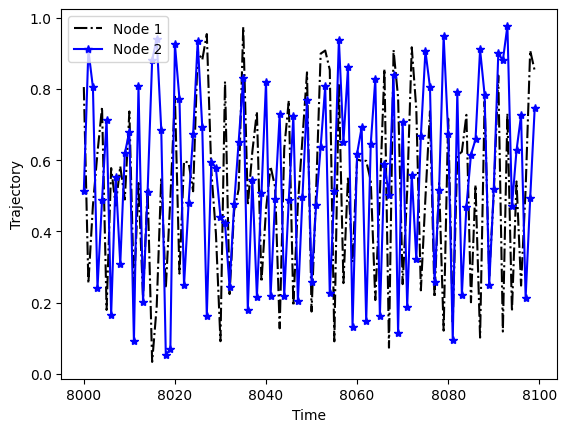

In [10]:
view_start = 8*10**3
view_end = view_start+100
plt.figure()
plt.plot(range(view_start,view_end), x_next_circ[view_start:view_end,0], 'k-.', label = "Node 1")
plt.plot(range(view_start,view_end), x_next_circ[view_start:view_end,5], 'b-*', label = "Node 2")
plt.xlabel("Time")
plt.ylabel("Trajectory")
plt.legend()
plt.show()

In [11]:
# Convert to DataFrame (columns 1 to N)
df = pd.DataFrame(x_next_log, columns=[f"Node_{i+1}" for i in range(x_next_log.shape[1])])

# Compute pairwise Pearson correlation
corr_matrix_df_circ = df.corr(method="pearson")
np.fill_diagonal(corr_matrix_df_circ.values, 0)
print(corr_matrix_df_circ)

           Node_1    Node_2    Node_3    Node_4    Node_5    Node_6    Node_7  \
Node_1   0.000000  0.436632  0.189490  0.104337 -0.010229 -0.003720  0.016268   
Node_2   0.436632  0.000000  0.270886  0.129309  0.065009  0.007419 -0.004048   
Node_3   0.189490  0.270886  0.000000  0.194744  0.001453  0.027785  0.015659   
Node_4   0.104337  0.129309  0.194744  0.000000 -0.066817 -0.040942  0.010285   
Node_5  -0.010229  0.065009  0.001453 -0.066817  0.000000  0.285641  0.157112   
Node_6  -0.003720  0.007419  0.027785 -0.040942  0.285641  0.000000  0.264594   
Node_7   0.016268 -0.004048  0.015659  0.010285  0.157112  0.264594  0.000000   
Node_8   0.002134  0.016072  0.037749  0.001536  0.159062  0.163524  0.452844   
Node_9  -0.040449  0.006601 -0.073697  0.095268  0.091355 -0.083379  0.008790   
Node_10  0.016591 -0.039503  0.046312 -0.005686  0.019122  0.033469  0.048876   
Node_11 -0.001187  0.035417  0.015378  0.024585  0.036216  0.012863  0.014465   
Node_12  0.011313 -0.004270 

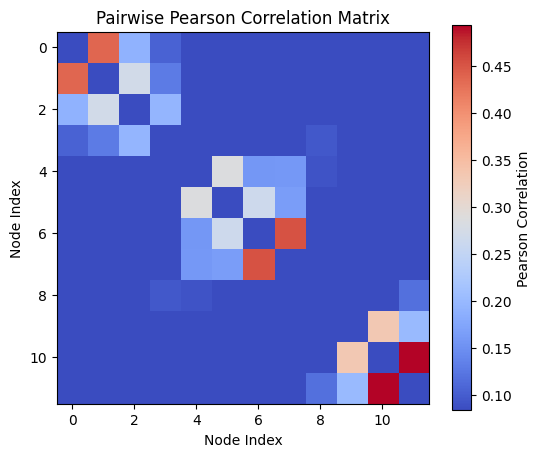

In [12]:
plt.figure(figsize=(6, 5))
plt.imshow(abs(corr_matrix_df_circ), cmap="coolwarm", vmin=abs(np.min(corr_matrix_df_circ)), vmax=abs(np.max(corr_matrix_df_circ)))
plt.colorbar(label="Pearson Correlation")
plt.title("Pairwise Pearson Correlation Matrix")
plt.xlabel("Node Index")
plt.ylabel("Node Index")
plt.show()